In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_temperatur = pd.read_csv("FreiburgTemperatur.csv")
df_temperatur["category"] = pd.to_datetime(df_temperatur["category"], format="mixed")
df_temperatur = df_temperatur.rename(columns={"category": "Datum"})
df_temperatur = df_temperatur.set_index("Datum").sort_index()

df_niederschlag = pd.read_csv("FreiburgNiederschlag.csv")
df_niederschlag["category"] = pd.to_datetime(df_niederschlag["category"], format="mixed")
df_niederschlag = df_niederschlag.rename(columns={"category": "Datum"})
df_niederschlag = df_niederschlag.set_index("Datum").sort_index()

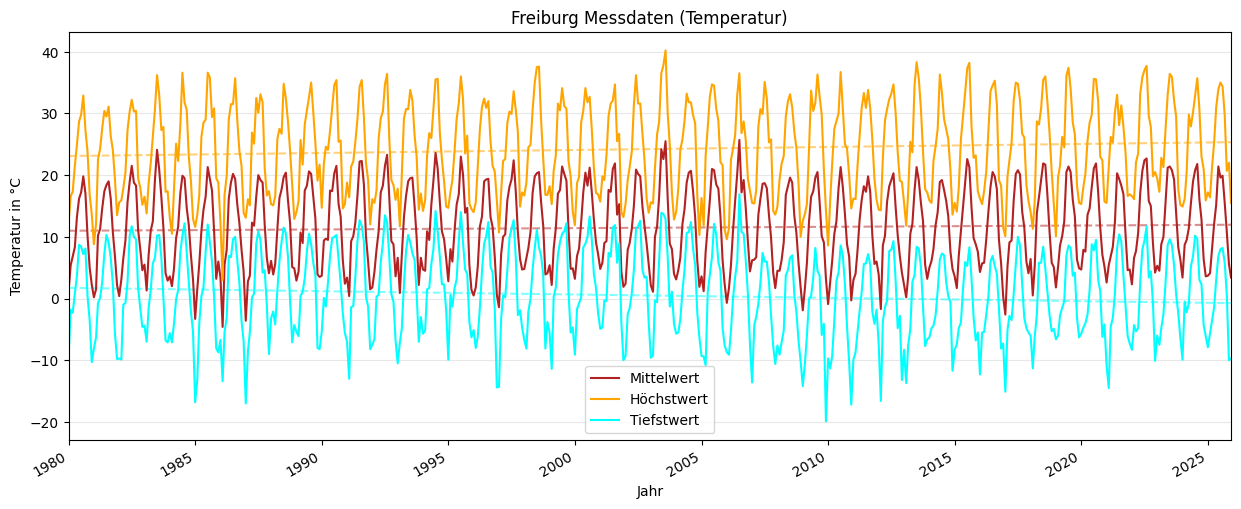

In [ ]:
series = df_temperatur.copy()
fig, ax = plt.subplots(figsize=(15, 6))

x = mdates.date2num(series.index)
p = np.poly1d(np.polyfit(x, series["Mittelwert"], 1))
ax.plot(x, p(x), color="firebrick", alpha=0.5, linestyle="--")
p = np.poly1d(np.polyfit(x, series["Höchstwert"], 1))
ax.plot(x, p(x), color="orange", alpha=0.5, linestyle="--")
p = np.poly1d(np.polyfit(x, series["Tiefstwert"], 1))
ax.plot(x, p(x), color="cyan", alpha=0.5, linestyle="--")
ax.margins(x=0)

series[["Mittelwert", "Höchstwert", "Tiefstwert"]].plot(ax=ax, color=["firebrick", "orange", "cyan"])

ax.set(
    title="Freiburg Messdaten (Temperatur)",
    xlabel="Jahr",
    ylabel="Temperatur in °C",
)
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.show()

# fig.savefig("temp_plot", dpi=300, bbox_inches="tight")

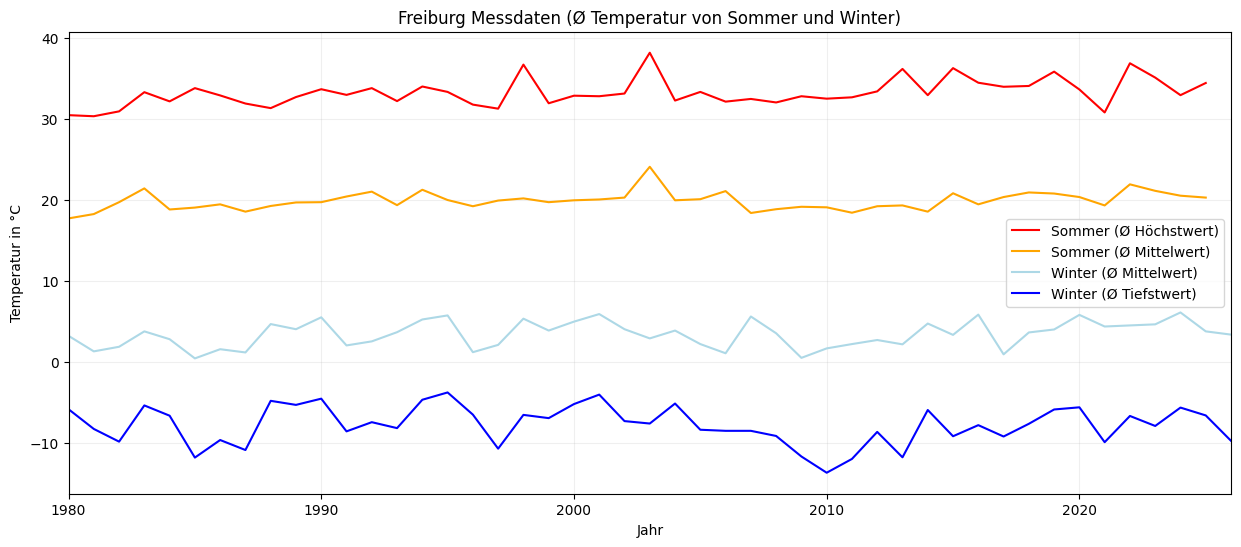

,Jahr,Höchstwert
0,2003,38.166667
1,2022,36.866667
2,1998,36.700000
3,2015,36.266667
4,2013,36.166667


,Jahr,Mittelwert
0,2003,24.100000
1,2022,21.933333
2,1983,21.433333
3,1994,21.266667
4,2023,21.133333


,Jahr,Tiefstwert
0,2010,-13.633333
1,2011,-11.933333
2,1985,-11.766667
3,2013,-11.733333
4,2009,-11.633333


,Jahr,Mittelwert
0,1985,0.466667
1,2009,0.533333
2,2017,0.966667
3,2006,1.100000
4,1987,1.200000


In [ ]:
series = df_temperatur.copy()


def seasons(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [6, 7, 8]:
        return "Sommer"
    else:
        return None


series["Jahr"] = series.index.year
series["Saison"] = series.index.map(seasons)
series.loc[series.index.month == 12, "Jahr"] += 1

series = series[series["Saison"].isin(["Sommer", "Winter"])]

series = (
    series.groupby(["Jahr", "Saison"])
    .agg({"Mittelwert": "mean", "Höchstwert": "mean", "Tiefstwert": "mean"})
    .reset_index()
)

fig, ax = plt.subplots(figsize=(15, 6))

summer = series[series["Saison"] == "Sommer"]
ax.plot(summer["Jahr"], summer["Höchstwert"], label="Sommer (Ø Höchstwert)", color="red")
ax.plot(summer["Jahr"], summer["Mittelwert"], label="Sommer (Ø Mittelwert)", color="orange")

winter = series[series["Saison"] == "Winter"]
ax.plot(
    winter["Jahr"],
    winter["Mittelwert"],
    label="Winter (Ø Mittelwert)",
    color="lightblue",
)
ax.plot(winter["Jahr"], winter["Tiefstwert"], label="Winter (Ø Tiefstwert)", color="blue")

ax.set(
    title="Freiburg Messdaten (Ø Temperatur von Sommer und Winter)",
    xlabel="Jahr",
    ylabel="Temperatur in °C",
)
ax.margins(x=0)
ax.legend()
ax.grid(True, alpha=0.2)
plt.show()

# fig.savefig("temp_saison_plot", dpi=300, bbox_inches="tight")

display(
    series[series["Saison"] == "Sommer"]
    .sort_values(by="Höchstwert", ascending=False)
    .reset_index()
    .head(5)[["Jahr", "Höchstwert"]]
)
display(
    series[series["Saison"] == "Sommer"]
    .sort_values(by="Mittelwert", ascending=False)
    .reset_index()
    .head(5)[["Jahr", "Mittelwert"]]
)

display(
    series[series["Saison"] == "Winter"]
    .sort_values(by="Tiefstwert", ascending=True)
    .reset_index()
    .head(5)[["Jahr", "Tiefstwert"]]
)
display(
    series[series["Saison"] == "Winter"]
    .sort_values(by="Mittelwert", ascending=True)
    .reset_index()
    .head(5)[["Jahr", "Mittelwert"]]
)

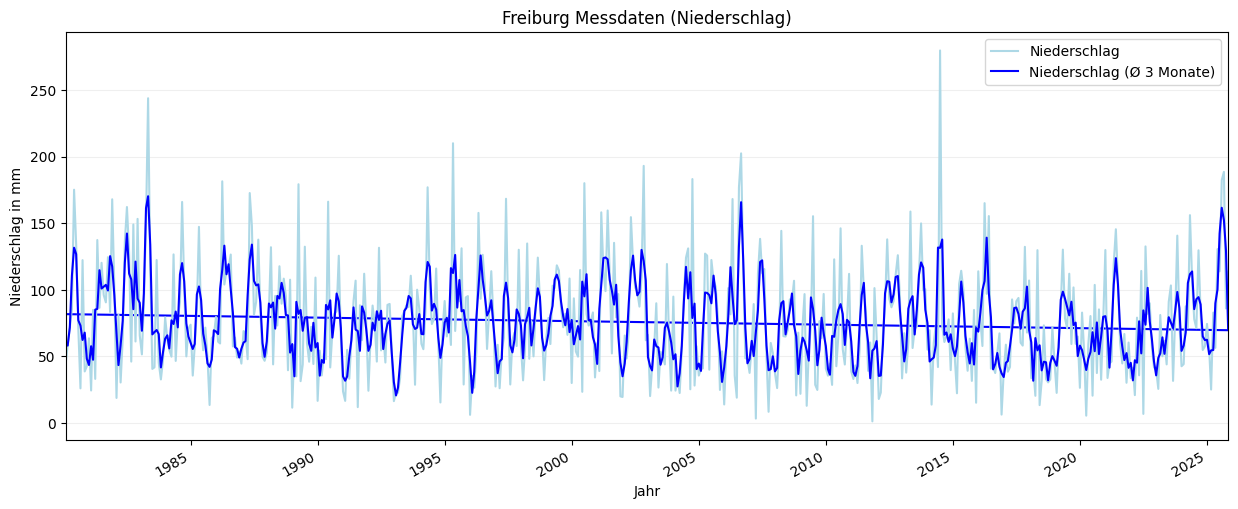

,Niederschlag,Niederschlag (Ø 3 Monate)
Datum,,
1983-05-01,243.8,170.200000
2006-09-01,202.4,165.733333
2025-08-01,182.3,161.533333
1983-04-01,149.7,161.300000
2025-09-01,188.5,152.233333


In [ ]:
series = df_niederschlag.copy()

series["Niederschlag (Ø 3 Monate)"] = (
    series["Niederschlag"] + series["Niederschlag"].shift(1) + series["Niederschlag"].shift(-1)
) / 3
fig, ax = plt.subplots(figsize=(15, 6))

series = series.dropna()
x = mdates.date2num(series.index)
p = np.poly1d(np.polyfit(x, series["Niederschlag (Ø 3 Monate)"], 1))
ax.plot(x, p(x), color="blue")
ax.margins(x=0)

series[["Niederschlag", "Niederschlag (Ø 3 Monate)"]].plot(ax=ax, color=["lightblue", "blue"])
ax.set(
    title="Freiburg Messdaten (Niederschlag)",
    xlabel="Jahr",
    ylabel="Niederschlag in mm",
)
ax.grid(True, axis="y", alpha=0.2)
plt.show()

# fig.savefig("niederschlag_plot", dpi=300, bbox_inches="tight")

series.sort_values(by="Niederschlag (Ø 3 Monate)", ascending=False).head(5)

,Mittelwert (1980 - 2000),Niederschlag (1980 - 2000),Mittelwert (2001 - 2025),Niederschlag (2001 - 2025),Mittelwert (2025),Niederschlag (2025),ΔT (2025),%T (2025),ΔN (2025),%N (2025),ΔT (2001 - 2025),%T (2001 - 2025),ΔN (2001 - 2025),%N (2001 - 2025)
Datum,,,,,,,,,,,,,,
Jan,2.47,52.11,2.88,53.25,3.7,74.3,1.23,50.00,22.19,42.57,0.41,16.72,1.13,2.17
Feb,3.51,51.88,4.07,45.50,4.1,55.5,0.59,16.82,3.62,6.99,0.56,15.88,-6.38,-12.29
Mar,7.47,60.85,7.33,55.91,7.9,25.0,0.43,5.80,-35.85,-58.92,-0.13,-1.79,-4.94,-8.12
Apr,10.58,76.29,11.10,64.43,12.1,82.8,1.52,14.36,6.51,8.54,0.51,4.87,-11.86,-15.54
May,15.16,110.23,15.15,100.64,15.2,56.3,0.04,0.28,-53.93,-48.92,-0.00,-0.02,-9.59,-8.70
Jun,18.06,101.78,19.31,86.60,21.4,130.5,3.34,18.51,28.72,28.22,1.25,6.93,-15.18,-14.92
Jul,20.55,97.91,20.80,86.30,19.6,113.8,-0.95,-4.63,15.89,16.23,0.25,1.20,-11.61,-11.86
Aug,20.39,78.84,20.20,89.35,19.9,182.3,-0.49,-2.38,103.46,131.23,-0.19,-0.93,10.52,13.34
Sep,16.37,86.13,15.98,70.82,15.5,188.5,-0.87,-5.30,102.37,118.86,-0.39,-2.39,-15.31,-17.77


,ΔT (2025),%T (2025),ΔN (2025),%N (2025)
Datum,,,,
Jan,1.23,50.00,22.19,42.57
Feb,0.59,16.82,3.62,6.99
Mar,0.43,5.80,-35.85,-58.92
Apr,1.52,14.36,6.51,8.54
May,0.04,0.28,-53.93,-48.92
Jun,3.34,18.51,28.72,28.22
Jul,-0.95,-4.63,15.89,16.23
Aug,-0.49,-2.38,103.46,131.23
Sep,-0.87,-5.30,102.37,118.86


,ΔT (2001 - 2025),%T (2001 - 2025),ΔN (2001 - 2025),%N (2001 - 2025)
Datum,,,,
Jan,0.41,16.72,1.13,2.17
Feb,0.56,15.88,-6.38,-12.29
Mar,-0.13,-1.79,-4.94,-8.12
Apr,0.51,4.87,-11.86,-15.54
May,-0.00,-0.02,-9.59,-8.70
Jun,1.25,6.93,-15.18,-14.92
Jul,0.25,1.20,-11.61,-11.86
Aug,-0.19,-0.93,10.52,13.34
Sep,-0.39,-2.39,-15.31,-17.77


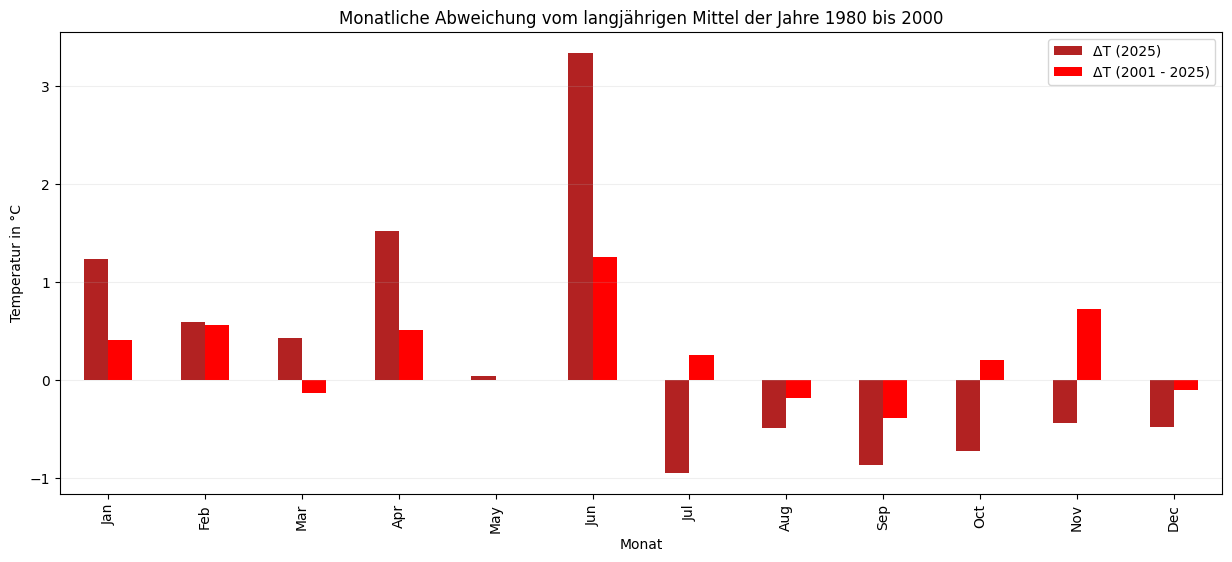

In [ ]:
def gen_df(start: str, end: str, name_1: str, name_2: str):
    df_1 = (
        df_temperatur.loc[start:end]
        .resample("ME")
        .mean()
        .groupby(lambda x: x.month)
        .mean()[["Mittelwert"]]
        .rename(columns={"Mittelwert": name_1})
    )

    df_2 = (
        df_niederschlag.loc[start:end]
        .resample("ME")
        .mean()
        .groupby(lambda x: x.month)
        .mean()
        .rename(columns={"Niederschlag": name_2})
    )

    return df_1.join(df_2)


df_focus_2025 = gen_df("2025-01-01", "2025-12-31", "Mittelwert (2025)", "Niederschlag (2025)")
df_focus_2000 = gen_df("2001-01-01", "2024-12-31", "Mittelwert (2001 - 2025)", "Niederschlag (2001 - 2025)")
df_focus_1980 = gen_df("1980-01-01", "2000-12-31", "Mittelwert (1980 - 2000)", "Niederschlag (1980 - 2000)")

df_comparison = df_focus_1980.join(df_focus_2000)
df_comparison = df_comparison.join(df_focus_2025)

df_comparison["ΔT (2025)"] = df_comparison["Mittelwert (2025)"] - df_comparison["Mittelwert (1980 - 2000)"]
df_comparison["%T (2025)"] = 100 * (df_comparison["Mittelwert (2025)"] / df_comparison["Mittelwert (1980 - 2000)"] - 1)
df_comparison["ΔN (2025)"] = df_comparison["Niederschlag (2025)"] - df_comparison["Niederschlag (1980 - 2000)"]
df_comparison["%N (2025)"] = 100 * (
    df_comparison["Niederschlag (2025)"] / df_comparison["Niederschlag (1980 - 2000)"] - 1
)

df_comparison["ΔT (2001 - 2025)"] = (
    df_comparison["Mittelwert (2001 - 2025)"] - df_comparison["Mittelwert (1980 - 2000)"]
)
df_comparison["%T (2001 - 2025)"] = 100 * (
    df_comparison["Mittelwert (2001 - 2025)"] / df_comparison["Mittelwert (1980 - 2000)"] - 1
)
df_comparison["ΔN (2001 - 2025)"] = (
    df_comparison["Niederschlag (2001 - 2025)"] - df_comparison["Niederschlag (1980 - 2000)"]
)
df_comparison["%N (2001 - 2025)"] = 100 * (
    df_comparison["Niederschlag (2001 - 2025)"] / df_comparison["Niederschlag (1980 - 2000)"] - 1
)

df_comparison = df_comparison.round(2)
df_comparison.index = df_comparison.index.map(lambda x: pd.to_datetime(x, format="%m").strftime("%b"))

display(df_comparison)
display(df_comparison.iloc[:, 6:10])
display(df_comparison.iloc[:, 10:])

fig, ax = plt.subplots(figsize=(15, 6))
df_comparison.iloc[:, [6, 10]].plot(kind="bar", ax=ax, color=["firebrick", "red"])
ax.set(
    title="Monatliche Abweichung vom langjährigen Mittel der Jahre 1980 bis 2000",
    xlabel="Monat",
    ylabel="Temperatur in °C",
)
ax.grid(True, axis="y", alpha=0.2)
plt.show()

# fig.savefig("temp_abweichungen_plot", dpi=300, bbox_inches="tight")

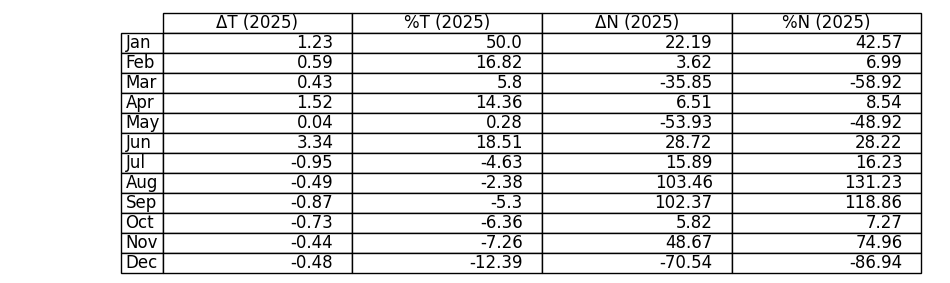

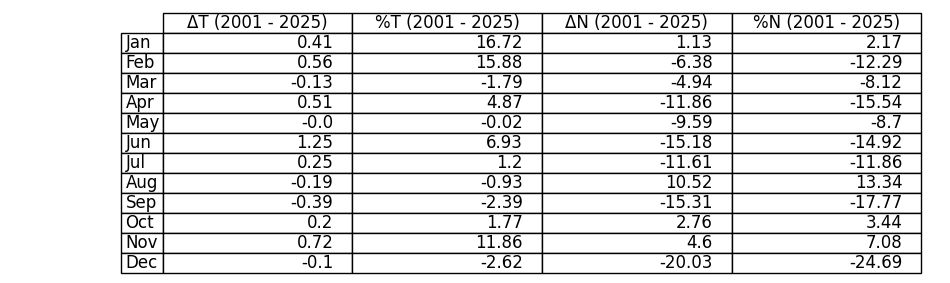

In [6]:
from pandas.plotting import table


def plot_df(df: pd.DataFrame):
    fig, ax = plt.subplots(figsize=(12, 2))
    ax.xaxis.set_visible(False)
    ax.yaxis.set_visible(False)
    ax.set_frame_on(False)
    tabla = table(ax, df, loc="upper right", colWidths=[0.17] * len(df.columns))
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(12)
    tabla.scale(1.2, 1.2)


plot_df(df_comparison.iloc[:, 6:10])
plot_df(df_comparison.iloc[:, 10:])